# 02 — Target Policy Sensitivity, Unknown-Period Alarm Burden, and Representative Timelines

1. Exports and plots representative timelines showing raw annotations, source timestamps, consensus target,
   and Ampli1-threshold predictions around failure onset and recovery (including unknown transition seconds).
2. Reports sensitivity to annotation-age choices (`3, 4, 5, 7 s`) without selecting the policy that gives the
   best test result (`4 s` remains primary).
3. Preserves uncertain periods as uncertain and reports their alarm burden separately (highlighting the 13
   threshold-alarm starts during unknown periods alongside 0 starts during known-normal exposure).

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

import common as C

C.ensure_dirs()
df_raw = C.load_raw()
ep_cand = pd.read_csv(C.OUT / "episodes_candidate.csv")
manifest = pd.read_csv(C.OUT / "split_manifest.csv")

In [2]:
# Annotation-age sensitivity (3, 4, 5, 7 seconds) — 4s is primary, never cherry-picking test score
sens_rows = []
primary_aligned = None
primary_thr = None

for max_age in [3.0, 4.0, 5.0, 7.0]:
    al, fcols, vcols = C.build_aligned(
        df_raw, age_limit_s=C.AGE_LIMIT_S, label_max_age_s=max_age, keep_audit=(max_age == 4.0)
    )
    split, man = C.build_split(al, ep_cand, context_s=10, partition_gap_s=30)
    al["split"] = split

    # Fit Ampli1 threshold on train+val for this policy
    tr_v = al.loc[al["split"].isin(["train"]) & al["target"].notna(), "Ampli1_InputPower"].dropna()
    val_df = al.loc[al["split"].eq("validation") & al["target"].notna() & al["Ampli1_InputPower"].notna()]
    cands = np.unique(np.round(np.quantile(tr_v, np.linspace(0.005, 0.995, 300)), 4))
    best_thr, best_vf1 = float(cands[0]), -1.0
    for c in cands:
        p = (val_df["Ampli1_InputPower"] <= c).astype(int)
        f1 = (
            2 * ((p == 1) & (val_df["target"] == 1)).sum()
            / max(1, (p == 1).sum() + (val_df["target"] == 1).sum())
        )
        if f1 > best_vf1:
            best_vf1 = float(f1)
            best_thr = float(c)

    test_tl = al.loc[al["split"].eq("test")].copy()
    test_tl["prediction"] = np.where(
        test_tl["Ampli1_InputPower"].notna(),
        (test_tl["Ampli1_InputPower"] <= best_thr).astype(float),
        np.nan,
    )
    test_ev = man.loc[man["split"].eq("test")]
    ev_res = C.evaluate_predictions(test_tl, test_ev, f"Ampli1_Threshold (age={max_age}s)", "ampli1_only")

    ep_cov = sum(
        int(al.loc[al["Timestamp"].between(r.first_observed_failure, r.last_observed_failure), "target"].eq(1).sum() > 0)
        for r in ep_cand.itertuples()
    )
    sens_rows.append({
        "label_max_age_s": max_age,
        "is_primary": max_age == 4.0,
        "normal_seconds_all": int(al["target"].eq(0).sum()),
        "failure_seconds_all": int(al["target"].eq(1).sum()),
        "unknown_seconds_all": int(al["target"].isna().sum()),
        "episodes_with_pos_label": f"{ep_cov}/{len(ep_cand)}",
        "selected_val_threshold_dBm": best_thr,
        "test_f1": ev_res["f1"],
        "test_event_recall": ev_res["event_recall"],
        "false_alarm_starts_normal": ev_res["false_alarm_starts"],
        "alarm_starts_unknown": ev_res["alarm_starts_unknown_target"],
        "normal_eval_hours": ev_res["normal_evaluation_hours"],
    })
    if max_age == 4.0:
        primary_aligned = al.copy()
        primary_thr = best_thr

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv(C.OUT / "annotation_age_sensitivity.csv", index=False)
print("Annotation-age sensitivity (primary = 4.0 s):")
print(sens_df.to_string(index=False))

Annotation-age sensitivity (primary = 4.0 s):
 label_max_age_s  is_primary  normal_seconds_all  failure_seconds_all  unknown_seconds_all episodes_with_pos_label  selected_val_threshold_dBm  test_f1  test_event_recall  false_alarm_starts_normal  alarm_starts_unknown  normal_eval_hours
             3.0       False               33530                  967                 1235                 131/131                       -38.0      1.0                1.0                          0                    13             0.2803
             4.0        True               33576                  968                 1188                 131/131                       -38.0      1.0                1.0                          0                    13             0.2808
             5.0       False               33608                  968                 1156                 131/131                       -38.0      1.0                1.0                          0                    13             0.281


Primary (4s) Test Ampli1 Threshold (-38.0 dBm): normal FA starts = 0, unknown alarm starts = 13


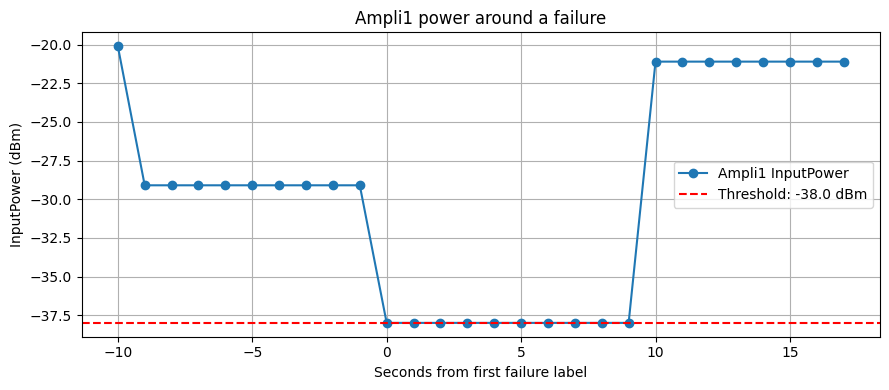

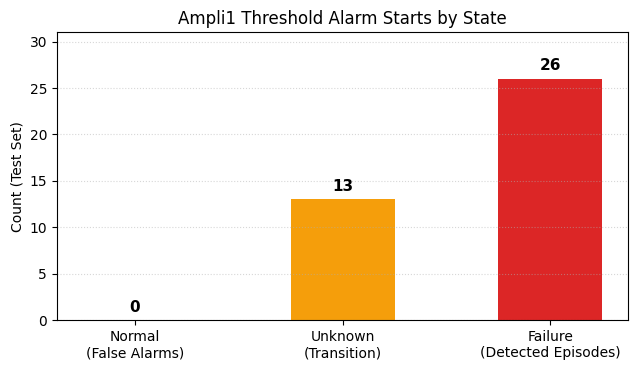

Saved representative_timelines.csv and figures/representative_timelines.png


In [3]:
# Representative timelines around test episode onset, recovery, and unknown-target alarms
test_tl = primary_aligned.loc[primary_aligned["split"].eq("test")].sort_values("Timestamp").copy()
test_tl["ampli1_pred"] = np.where(
    test_tl["Ampli1_InputPower"].notna(),
    (test_tl["Ampli1_InputPower"] <= primary_thr).astype(float),
    np.nan,
)
pos = test_tl["ampli1_pred"].eq(1).fillna(False)
prev_pos = pos.shift(1, fill_value=False)
consec = test_tl["Timestamp"].diff().eq(1)
test_tl["alarm_start"] = pos & ~(prev_pos & consec)
test_tl["unknown_alarm_start"] = test_tl["alarm_start"] & test_tl["target"].isna()

print(
    f"\nPrimary (4s) Test Ampli1 Threshold ({primary_thr} dBm): "
    f"normal FA starts = {int((test_tl['alarm_start'] & test_tl['target'].eq(0)).sum())}, "
    f"unknown alarm starts = {int(test_tl['unknown_alarm_start'].sum())}"
)

test_events = manifest.loc[manifest["split"].eq("test")].reset_index(drop=True)
# Pick 3 representative test episodes: first, middle (with unknown alarm if any), and longest
rep_ids = [
    int(test_events.iloc[0]["episode_id"]),
    int(test_events.iloc[len(test_events) // 2]["episode_id"]),
    int(test_events.loc[test_events["observed_span_s"].idxmax(), "episode_id"]),
]
rep_events = test_events.loc[test_events["episode_id"].isin(rep_ids)]

audit_cols = [c for c in primary_aligned.columns if c.endswith("_annotation_status") or c.endswith("_source_timestamp")]
keep_cols = ["Timestamp", "target", "label_reason", "Ampli1_InputPower", "ampli1_pred", "alarm_start", "unknown_alarm_start"] + audit_cols

timeline_exports = []
for ev in rep_events.itertuples():
    win = test_tl.loc[test_tl["Timestamp"].between(ev.first_observed_failure - 10, ev.last_observed_failure + 10), keep_cols].copy()
    win["episode_id"] = ev.episode_id
    win["rel_s"] = win["Timestamp"] - ev.first_observed_failure
    timeline_exports.append(win)


win = timeline_exports[0]

plt.figure(figsize=(9, 4))


plt.plot(
    win["rel_s"],
    win["Ampli1_InputPower"],
    marker="o",
    label="Ampli1 InputPower"
)

plt.axhline(
    primary_thr,
    color="red",
    linestyle="--",
    label=f"Threshold: {primary_thr} dBm"
)

plt.xlabel("Seconds from first failure label")
plt.ylabel("InputPower (dBm)")
plt.title("Ampli1 power around a failure")
plt.legend()
plt.grid()
plt.tight_layout()

plt.savefig(C.FIG_DIR / "representative_timelines.png", dpi=150)
plt.show()

# الرسمة الثانية: Bar Chart بسيط يوضح عدد الإنذارات في كل حالة
cats = ["Normal\n(False Alarms)", "Unknown\n(Transition)", "Failure\n(Detected Episodes)"]
vals = [
    int((test_tl["alarm_start"] & test_tl["target"].eq(0)).sum()),
    int(test_tl["unknown_alarm_start"].sum()),
    len(test_events),
]
plt.figure(figsize=(6.5, 3.8))
bars = plt.bar(cats, vals, color=["#16a34a", "#f59e0b", "#dc2626"], width=0.5)
for b in bars:
    plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{int(b.get_height())}",
             ha="center", va="bottom", fontsize=11, fontweight="bold")
plt.ylim(0, max(vals) + 5)
plt.ylabel("Count (Test Set)")
plt.title("Ampli1 Threshold Alarm Starts by State")
plt.grid(axis="y", linestyle=":", alpha=0.5)
plt.tight_layout()
plt.savefig(C.FIG_DIR / "alarm_starts_summary.png", dpi=150)
plt.show()

pd.concat(timeline_exports, ignore_index=True).to_csv(C.OUT / "representative_timelines.csv", index=False)
print("Saved representative_timelines.csv and figures/representative_timelines.png")